# Comparative Implementation of Machine Learning Regression Algorithms
**Dataset:** Salary Dataset – Simple Linear Regression (Kaggle, `abhishek14398`) | **Target:** `Salary` | **Feature:** `YearsExperience`

**Algorithms:** Linear Regression · Decision Tree · Random Forest · Neural Network (PyTorch, GPU) · XGBoost (GPU) · KNN

**Structure**
1. Setup, data loading, EDA, preprocessing, 80:20 split
2. **Part A – Handwritten implementation** (theory, equations, step-by-step calculations on a 6-row sample)
3. **Part B – Python implementation** (same data, same split, same feature/target)
4. Evaluation (MAE, MSE, RMSE, R²), comparison table, actual-vs-predicted plots
5. Strengths/limitations and the best model

> Runtime → Change runtime type → **T4 GPU** before running.

## 1. Setup

In [1]:
!pip -q install kagglehub
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn as nn, os, glob, kagglehub
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only (enable T4 GPU)")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

Device: cuda | Tesla T4


## 2. Load dataset, EDA and preprocessing

In [2]:
path = kagglehub.dataset_download("abhishek14398/salary-dataset-simple-linear-regression")
print("Path to dataset files:", path)
csv = glob.glob(os.path.join(path, "*.csv"))[0]
df = pd.read_csv(csv)
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]       # drop the index column
print(df.shape); display(df.head()); display(df.describe())
print("Missing values:\n", df.isna().sum().to_string(), "\nDuplicates:", df.duplicated().sum())

Using Colab cache for faster access to the 'salary-dataset-simple-linear-regression' dataset.
Path to dataset files: /kaggle/input/salary-dataset-simple-linear-regression
(30, 2)


,YearsExperience,Salary
0,1.2000,"39,344.0000"
1,1.4000,"46,206.0000"
2,1.6000,"37,732.0000"
3,2.1000,"43,526.0000"
4,2.3000,"39,892.0000"


,YearsExperience,Salary
count,30.0000,30.0000
mean,5.4133,"76,004.0000"
std,2.8379,"27,414.4298"
min,1.2000,"37,732.0000"
25%,3.3000,"56,721.7500"
50%,4.8000,"65,238.0000"
75%,7.8000,"100,545.7500"
max,10.6000,"122,392.0000"


Missing values:
 YearsExperience    0
Salary             0 
Duplicates: 0


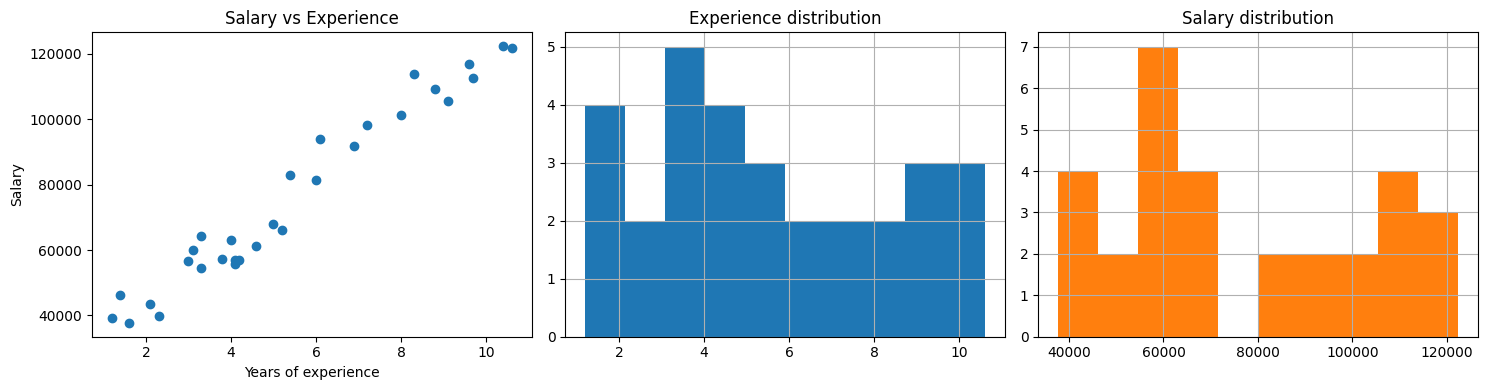

Pearson correlation: 0.9782


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(df.YearsExperience, df.Salary, c="tab:blue"); ax[0].set(title="Salary vs Experience", xlabel="Years of experience", ylabel="Salary")
df.YearsExperience.hist(ax=ax[1], bins=10); ax[1].set_title("Experience distribution")
df.Salary.hist(ax=ax[2], bins=10, color="tab:orange"); ax[2].set_title("Salary distribution")
plt.tight_layout(); plt.show()
print("Pearson correlation:", round(df.YearsExperience.corr(df.Salary), 4))

**Preprocessing decisions**
- No missing values/duplicates, so no imputation is needed; the unnamed index column is dropped.
- One numeric feature (`YearsExperience`) → one target (`Salary`). The **same 80:20 split (`random_state=42`)** is used by every model.
- **Scaling:** `StandardScaler` (fit on the training set only, to avoid leakage) for Linear Regression, KNN and the Neural Network. Decision Tree, Random Forest and XGBoost are split-based and scale-invariant, so they use raw values.

In [4]:
FEATURES, TARGET = ["YearsExperience"], "Salary"
X, y = df[FEATURES].values, df[TARGET].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")

Train: 24 rows | Test: 6 rows


# Part A – Handwritten Implementation
All calculations below are done **step by step with plain NumPy arithmetic (no ML library)** on a small sample of **6 rows drawn from the training set**, then checked against a library result. The same 6 points are reused for every algorithm, and the first test row is the point to predict.

In [5]:
sample = (pd.DataFrame(X_train, columns=["x"]).assign(y=y_train)
          .sample(6, random_state=7).sort_values("x").reset_index(drop=True))
sample.index = sample.index + 1; sample.index.name = "i"
xs, ys = sample.x.values, sample.y.values
x_new, y_new = X_test[0, 0], y_test[0]          # test point to predict
display(sample); print(f"Test point: x = {x_new}  (actual salary = {y_new:,.0f})")

,x,y
i,,
1,1.6000,"37,732.0000"
2,2.1000,"43,526.0000"
3,4.1000,"56,958.0000"
4,4.6000,"61,112.0000"
5,5.2000,"66,030.0000"
6,8.8000,"109,432.0000"


Test point: x = 9.7  (actual salary = 112,636)


## A1. Linear Regression (Ordinary Least Squares)
**Procedure:** fit a straight line $\hat y=\beta_0+\beta_1x$ that minimises the sum of squared residuals.

$$\beta_1=\frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sum_i (x_i-\bar x)^2},\qquad \beta_0=\bar y-\beta_1\bar x,\qquad \text{(matrix form)}\ \ \boldsymbol\beta=(X^TX)^{-1}X^Ty$$

In [6]:
n = len(xs); xbar, ybar = xs.mean(), ys.mean()
t = pd.DataFrame({"x": xs, "y": ys, "x-x̄": xs-xbar, "y-ȳ": ys-ybar})
t["(x-x̄)(y-ȳ)"] = t["x-x̄"]*t["y-ȳ"]; t["(x-x̄)²"] = t["x-x̄"]**2
display(t)
Sxy, Sxx = t["(x-x̄)(y-ȳ)"].sum(), t["(x-x̄)²"].sum()
b1 = Sxy/Sxx; b0 = ybar - b1*xbar
print(f"x̄ = {xbar:.4f}, ȳ = {ybar:,.2f}\nSxy = {Sxy:,.2f}, Sxx = {Sxx:.4f}")
print(f"β1 = Sxy/Sxx = {b1:,.2f}\nβ0 = ȳ - β1·x̄ = {b0:,.2f}")
print(f"Prediction for x={x_new}: ŷ = {b0:,.2f} + {b1:,.2f}×{x_new} = {b0+b1*x_new:,.2f}")
# matrix-form check + library check
Xd = np.c_[np.ones(n), xs]; beta = np.linalg.solve(Xd.T@Xd, Xd.T@ys)
lr_chk = LinearRegression().fit(xs.reshape(-1,1), ys)
print("Normal equation β:", beta.round(2), "| sklearn:", [round(lr_chk.intercept_,2), round(lr_chk.coef_[0],2)])

,x,y,x-x̄,y-ȳ,(x-x̄)(y-ȳ),(x-x̄)²
0,1.6000,"37,732.0000",-2.8000,"-24,733.0000","69,252.4000",7.8400
1,2.1000,"43,526.0000",-2.3000,"-18,939.0000","43,559.7000",5.2900
2,4.1000,"56,958.0000",-0.3000,"-5,507.0000","1,652.1000",0.0900
3,4.6000,"61,112.0000",0.2000,"-1,353.0000",-270.6000,0.0400
4,5.2000,"66,030.0000",0.8000,"3,565.0000","2,852.0000",0.6400
5,8.8000,"109,432.0000",4.4000,"46,967.0000","206,654.8000",19.3600


x̄ = 4.4000, ȳ = 62,465.00
Sxy = 323,700.40, Sxx = 33.2600
β1 = Sxy/Sxx = 9,732.42
β0 = ȳ - β1·x̄ = 19,642.34
Prediction for x=9.7: ŷ = 19,642.34 + 9,732.42×9.7 = 114,046.84
Normal equation β: [19642.34  9732.42] | sklearn: [np.float64(19642.34), np.float64(9732.42)]


## A2. Decision Tree Regression (CART)
**Procedure:** recursively choose the split threshold $t$ on feature $x$ that minimises the total squared error (variance) of the two children; the prediction in a leaf is the **mean** of its targets.

$$SSE(t)=\sum_{i\in L}(y_i-\bar y_L)^2+\sum_{i\in R}(y_i-\bar y_R)^2,\qquad \hat y_{leaf}=\frac1{|leaf|}\sum_{i\in leaf}y_i$$
Candidate thresholds are midpoints between consecutive sorted $x$ values. Splitting stops at `max_depth`.

In [7]:
def sse(v): return ((v - v.mean())**2).sum() if len(v) else 0.0

def split_table(x, y):
    o = np.argsort(x); x, y = x[o], y[o]; rows = []
    for t_ in (x[:-1] + x[1:]) / 2:
        L, R = y[x <= t_], y[x > t_]
        rows.append([t_, len(L), L.mean(), len(R), R.mean(), sse(L), sse(R), sse(L)+sse(R)])
    return pd.DataFrame(rows, columns=["threshold","nL","mean_L","nR","mean_R","SSE_L","SSE_R","SSE_total"])

print(f"Parent node: mean = {ys.mean():,.2f}, SSE = {sse(ys):,.2f}")
tbl = split_table(xs, ys); display(tbl)
best = tbl.loc[tbl.SSE_total.idxmin()]
print(f"Best first split: x <= {best.threshold:.3f}  (SSE {sse(ys):,.0f} → {best.SSE_total:,.0f})")

Parent node: mean = 62,465.00, SSE = 3,221,172,982.00


,threshold,nL,mean_L,nR,mean_R,SSE_L,SSE_R,SSE_total
0,1.8500,1,"37,732.0000",5,"67,411.6000",0.0000,"2,487,107,435.2000","2,487,107,435.2000"
1,3.1000,2,"40,629.0000",4,"73,383.0000","16,785,218.0000","1,773,955,076.0000","1,790,740,294.0000"
2,4.3500,3,"46,072.0000",3,"78,858.0000","194,542,712.0000","1,414,247,576.0000","1,608,790,288.0000"
3,4.9000,4,"49,832.0000",2,"87,731.0000","364,193,912.0000","941,866,802.0000","1,306,060,714.0000"
4,7.0000,5,"53,071.6000",1,"109,432.0000","574,094,075.2000",0.0000,"574,094,075.2000"


Best first split: x <= 7.000  (SSE 3,221,172,982 → 574,094,075)


In [8]:
def build_tree(x, y, depth, max_depth=2):
    if depth == max_depth or len(np.unique(x)) < 2: return float(y.mean())
    tb = split_table(x, y); b = tb.loc[tb.SSE_total.idxmin()]
    m = x <= b.threshold
    return {"t": b.threshold, "L": build_tree(x[m], y[m], depth+1, max_depth), "R": build_tree(x[~m], y[~m], depth+1, max_depth)}

def predict_tree(node, v):
    while isinstance(node, dict): node = node["L"] if v <= node["t"] else node["R"]
    return node

def show_tree(node, ind=0):
    if isinstance(node, dict):
        print("  "*ind + f"if x <= {node['t']:.3f}:"); show_tree(node["L"], ind+1)
        print("  "*ind + "else:");                      show_tree(node["R"], ind+1)
    else: print("  "*ind + f"→ predict {node:,.2f}")

tree2 = build_tree(xs, ys, 0, 2); show_tree(tree2)
print(f"\nPrediction for x={x_new}: {predict_tree(tree2, x_new):,.2f}")
print("sklearn check (max_depth=2):", round(DecisionTreeRegressor(max_depth=2, random_state=0).fit(xs.reshape(-1,1), ys).predict([[x_new]])[0], 2))

if x <= 7.000:
  if x <= 3.100:
    → predict 40,629.00
  else:
    → predict 61,366.67
else:
  → predict 109,432.00

Prediction for x=9.7: 109,432.00
sklearn check (max_depth=2): 109432.0


## A3. Random Forest Regression
**Procedure:** (1) draw $B$ bootstrap samples (sampling rows **with replacement**); (2) grow one decision tree on each (with 1 feature there is no feature sub-sampling); (3) **average** the trees' predictions. Averaging lowers variance.

$$\hat y(x)=\frac1B\sum_{b=1}^{B}T_b(x)$$

In [9]:
rng = np.random.default_rng(1); B = 3; preds_b = []
for b in range(1, B+1):
    idx = rng.integers(0, len(xs), len(xs))
    xb, yb = xs[idx], ys[idx]
    tr = build_tree(xb, yb, 0, 2); p = predict_tree(tr, x_new); preds_b.append(p)
    print(f"Tree {b}: bootstrap rows (i) = {sorted(idx+1)} | prediction = {p:,.2f}")
    show_tree(tr, 1)
print(f"\nForest prediction = mean({[round(p,2) for p in preds_b]}) = {np.mean(preds_b):,.2f}")

Tree 1: bootstrap rows (i) = [np.int64(1), np.int64(1), np.int64(3), np.int64(4), np.int64(5), np.int64(6)] | prediction = 109,432.00
  if x <= 7.000:
    if x <= 1.600:
      → predict 37,732.00
    else:
      → predict 61,366.67
  else:
    → predict 109,432.00
Tree 2: bootstrap rows (i) = [np.int64(2), np.int64(2), np.int64(3), np.int64(5), np.int64(6), np.int64(6)] | prediction = 109,432.00
  if x <= 7.000:
    if x <= 2.100:
      → predict 43,526.00
    else:
      → predict 61,494.00
  else:
    → predict 109,432.00
Tree 3: bootstrap rows (i) = [np.int64(2), np.int64(2), np.int64(3), np.int64(4), np.int64(4), np.int64(5)] | prediction = 66,030.00
  if x <= 2.100:
    → predict 43,526.00
  else:
    if x <= 4.600:
      → predict 59,727.33
    else:
      → predict 66,030.00

Forest prediction = mean([109432.0, 109432.0, 66030.0]) = 94,964.67


## A4. Neural Network Regression (1 – 2 – 1 MLP, one gradient-descent step)
**Architecture:** input $x$ → 2 hidden ReLU neurons → 1 linear output.

**Forward:** $z_j=w_{1j}x+b_{1j},\ h_j=\max(0,z_j),\ \hat y=\sum_j w_{2j}h_j+b_2$  
**Loss (MSE):** $L=\frac1n\sum(\hat y_i-y_i)^2$  
**Backward (chain rule):** $\frac{\partial L}{\partial\hat y_i}=\frac2n(\hat y_i-y_i)$, $\frac{\partial L}{\partial w_{2j}}=\sum_i \frac{\partial L}{\partial\hat y_i}h_{ij}$, $\frac{\partial L}{\partial b_2}=\sum_i\frac{\partial L}{\partial\hat y_i}$, $\delta_{ij}=\frac{\partial L}{\partial\hat y_i}w_{2j}\,\mathbb 1[z_{ij}>0]$, $\frac{\partial L}{\partial w_{1j}}=\sum_i\delta_{ij}x_i$, $\frac{\partial L}{\partial b_{1j}}=\sum_i\delta_{ij}$  
**Update:** $\theta\leftarrow\theta-\eta\,\nabla_\theta L$

Inputs and targets are standardised first (as in the Python implementation).

In [10]:
xm, xsd, ym, ysd = xs.mean(), xs.std(), ys.mean(), ys.std()
xn, yn = (xs - xm)/xsd, (ys - ym)/ysd; n = len(xn)
W1, b1v = np.array([0.5, 0.8]), np.array([0.1, -0.1]); W2, b2 = np.array([0.6, 0.4]), 0.05; eta = 0.1

def forward(x):
    z = np.outer(x, W1) + b1v; h = np.maximum(0, z); return z, h, h@W2 + b2
z, h, yhat = forward(xn); L0 = ((yhat-yn)**2).mean()
print("Standardised x:", xn.round(3)); print("Standardised y:", yn.round(3))
print("z (n×2):\n", z.round(3)); print("h = ReLU(z):\n", h.round(3))
print("ŷ:", yhat.round(3), "\nLoss before step:", round(L0, 4))

dy = 2/n*(yhat-yn)                        # dL/dŷ
gW2, gb2 = h.T@dy, dy.sum()
delta = np.outer(dy, W2)*(z > 0)          # dL/dz
gW1, gb1 = delta.T@xn, delta.sum(0)
print("\nGradients  dW2:", gW2.round(4), "db2:", round(gb2,4), "dW1:", gW1.round(4), "db1:", gb1.round(4))

W2n, b2n, W1n, b1n = W2-eta*gW2, b2-eta*gb2, W1-eta*gW1, b1v-eta*gb1
print("Updated  W1:", W1n.round(4), "b1:", b1n.round(4), "W2:", W2n.round(4), "b2:", round(b2n,4))
W1, b1v, W2, b2 = W1n, b1n, W2n, b2n
print("Loss after step:", round(((forward(xn)[2]-yn)**2).mean(), 4), "(should be lower)")
# verification with autograd
w1t = torch.tensor(W1n+eta*gW1, requires_grad=True); b1t = torch.tensor(b1n+eta*gb1, requires_grad=True)
w2t = torch.tensor(W2n+eta*gW2, requires_grad=True); b2t = torch.tensor(b2n+eta*gb2, requires_grad=True)
xt, yt = torch.tensor(xn), torch.tensor(yn)
((torch.relu(xt[:,None]*w1t + b1t)@w2t + b2t - yt)**2).mean().backward()
print("Autograd check dW2:", w2t.grad.numpy().round(4), "dW1:", w1t.grad.numpy().round(4))
xq = (x_new - xm)/xsd; print(f"Prediction for x={x_new} (after 1 step, un-scaled): {forward(np.array([xq]))[2][0]*ysd + ym:,.2f}")

Standardised x: [-1.189 -0.977 -0.127  0.085  0.34   1.869]
Standardised y: [-1.067 -0.817 -0.238 -0.058  0.154  2.027]
z (n×2):
 [[-0.495 -1.051]
 [-0.388 -0.882]
 [ 0.036 -0.202]
 [ 0.142 -0.032]
 [ 0.27   0.172]
 [ 1.034  1.395]]
h = ReLU(z):
 [[0.    0.   ]
 [0.    0.   ]
 [0.036 0.   ]
 [0.142 0.   ]
 [0.27  0.172]
 [1.034 1.395]]
ŷ: [0.05  0.05  0.072 0.135 0.281 1.229] 
Loss before step: 0.4646

Gradients  dW2: [-0.2509 -0.364 ] db2: 0.6055 dW1: [-0.2944 -0.1932] db1: [-0.0336 -0.0895]
Updated  W1: [0.5294 0.8193] b1: [ 0.1034 -0.091 ] W2: [0.6251 0.4364] b2: -0.0106
Loss after step: 0.3977 (should be lower)
Autograd check dW2: [-0.2509 -0.364 ] dW1: [-0.2944 -0.1932]
Prediction for x=9.7 (after 1 step, un-scaled): 98,707.68


## A5. XGBoost Regression (gradient boosting with second-order trees)
**Procedure:** start from a constant $\hat y^{(0)}=\bar y$. For each round $m$: compute gradients/hessians of the squared-error loss, grow a tree that maximises *Gain*, set leaf weights, and add the tree scaled by the learning rate $\eta$.

$$g_i=\hat y_i-y_i,\quad h_i=1,\quad w_{leaf}=-\frac{G}{H+\lambda},\quad Gain=\tfrac12\Big[\tfrac{G_L^2}{H_L+\lambda}+\tfrac{G_R^2}{H_R+\lambda}-\tfrac{(G_L+G_R)^2}{H_L+H_R+\lambda}\Big]-\gamma$$
$$\hat y^{(m)}=\hat y^{(m-1)}+\eta\,w_{leaf(x)}$$
Here: $\lambda=1,\ \gamma=0,\ \eta=0.3$, depth-1 trees (stumps), 2 rounds.

In [11]:
lam, gam, eta_x, rounds = 1.0, 0.0, 0.3, 2
pred = np.full(len(xs), ys.mean()); pred_new = ys.mean(); print(f"Round 0: base prediction ȳ = {ys.mean():,.2f}")
for m in range(1, rounds+1):
    g, hh = pred - ys, np.ones(len(ys)); G, H = g.sum(), hh.sum(); rows = []
    for t_ in (xs[:-1]+xs[1:])/2:
        mL = xs <= t_; GL, HL, GR, HR = g[mL].sum(), hh[mL].sum(), g[~mL].sum(), hh[~mL].sum()
        gain = 0.5*(GL**2/(HL+lam) + GR**2/(HR+lam) - G**2/(H+lam)) - gam
        rows.append([t_, GL, HL, GR, HR, gain])
    tb = pd.DataFrame(rows, columns=["threshold","G_L","H_L","G_R","H_R","Gain"]); display(tb)
    bt = tb.loc[tb.Gain.idxmax()]; mL = xs <= bt.threshold
    wL, wR = -bt.G_L/(bt.H_L+lam), -bt.G_R/(bt.H_R+lam)
    print(f"Round {m}: split x <= {bt.threshold:.3f} | w_L = {wL:,.2f}, w_R = {wR:,.2f}")
    pred = pred + eta_x*np.where(mL, wL, wR); pred_new = pred_new + eta_x*(wL if x_new <= bt.threshold else wR)
    print("  updated predictions:", pred.round(0))
print(f"\nXGBoost (2 rounds) prediction for x={x_new}: {pred_new:,.2f}")

Round 0: base prediction ȳ = 62,465.00


,threshold,G_L,H_L,G_R,H_R,Gain
0,1.8500,"24,733.0000",1.0000,"-24,733.0000",5.0000,"203,907,096.3333"
1,3.1000,"43,672.0000",2.0000,"-43,672.0000",4.0000,"508,598,289.0667"
2,4.3500,"49,179.0000",3.0000,"-49,179.0000",3.0000,"604,643,510.2500"
3,4.9000,"50,532.0000",4.0000,"-50,532.0000",2.0000,"680,928,806.4000"
4,7.0000,"46,967.0000",5.0000,"-46,967.0000",1.0000,"735,299,696.3333"


Round 1: split x <= 7.000 | w_L = -7,827.83, w_R = 23,483.50
  updated predictions: [60117. 60117. 60117. 60117. 60117. 69510.]


,threshold,G_L,H_L,G_R,H_R,Gain
0,1.8500,"22,384.6500",1.0000,"-27,081.3500",5.0000,"184,809,123.1844"
1,3.1000,"38,975.3000",2.0000,"-43,672.0000",4.0000,"442,327,717.8752"
2,4.3500,"42,133.9500",3.0000,"-46,830.6500",3.0000,"494,471,798.0467"
3,4.9000,"41,138.6000",4.0000,"-45,835.3000",2.0000,"517,808,586.4712"
4,7.0000,"35,225.2500",5.0000,"-39,921.9500",1.0000,"500,266,400.5411"


Round 2: split x <= 4.900 | w_L = -8,227.72, w_R = 15,278.43
  updated predictions: [57648. 57648. 57648. 57648. 64700. 74094.]

XGBoost (2 rounds) prediction for x=9.7: 74,093.58


## A6. K-Nearest Neighbours Regression
**Procedure:** (1) compute the distance from the query point to every training point; (2) pick the $k$ nearest; (3) predict their **average** target (lazy learner – no training phase).

$$d(x_q,x_i)=\sqrt{\sum_j (x_{qj}-x_{ij})^2}\ \ (=|x_q-x_i|\text{ for one feature}),\qquad \hat y(x_q)=\frac1k\sum_{i\in N_k(x_q)}y_i$$

In [12]:
k = 3
d = pd.DataFrame({"x": xs, "y": ys, "distance |x_q - x|": np.abs(xs - x_new)}, index=sample.index)
d["rank"] = d.iloc[:, 2].rank().astype(int); display(d.sort_values("rank"))
nn_ = d.nsmallest(k, "distance |x_q - x|")
print(f"k={k} nearest salaries: {nn_.y.values.tolist()}")
print(f"Prediction = ({' + '.join(f'{v:,.0f}' for v in nn_.y)}) / {k} = {nn_.y.mean():,.2f}")

,x,y,distance |x_q - x|,rank
i,,,,
6,8.8000,"109,432.0000",0.9000,1
5,5.2000,"66,030.0000",4.5000,2
4,4.6000,"61,112.0000",5.1000,3
3,4.1000,"56,958.0000",5.6000,4
2,2.1000,"43,526.0000",7.6000,5
1,1.6000,"37,732.0000",8.1000,6


k=3 nearest salaries: [109432.0, 66030.0, 61112.0]
Prediction = (109,432 + 66,030 + 61,112) / 3 = 78,858.00


# Part B – Python Implementation (full dataset, 80:20 split)
All models use the **same `X_train/X_test/y_train/y_test`**. Hyper-parameters of the tunable models are chosen by **5-fold cross-validation on the training set only** (the test set is never touched during tuning). Linear Regression has no hyper-parameters.

In [13]:
def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

cv5 = KFold(5, shuffle=True, random_state=SEED)
def tune(est, grid, jobs=-1): return GridSearchCV(est, grid, cv=cv5, scoring="neg_root_mean_squared_error", n_jobs=jobs).fit(X_train, y_train)

xgb_dev = dict(device="cuda") if DEVICE == "cuda" else {}
models = {
  "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train),
  "Decision Tree": tune(DecisionTreeRegressor(random_state=SEED),
                        {"max_depth": [2,3,4,5,None], "min_samples_leaf": [1,2,3]}),
  "Random Forest": tune(RandomForestRegressor(random_state=SEED),
                        {"n_estimators": [100,300], "max_depth": [2,3,5,None], "min_samples_leaf": [1,2]}),
  "KNN": tune(make_pipeline(StandardScaler(), KNeighborsRegressor()),
              {"kneighborsregressor__n_neighbors": list(range(1,10)), "kneighborsregressor__weights": ["uniform","distance"]}),
  "XGBoost": tune(XGBRegressor(tree_method="hist", random_state=SEED, **xgb_dev),
                  {"n_estimators": [100,300], "max_depth": [2,3], "learning_rate": [0.05,0.1,0.3]}, jobs=1),   # jobs=1: keep GPU access in a single process
}
for name, m in models.items():
    if isinstance(m, GridSearchCV): print(f"{name:14s} best params: {m.best_params_}")

Decision Tree  best params: {'max_depth': None, 'min_samples_leaf': 1}
Random Forest  best params: {'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 300}
KNN            best params: {'kneighborsregressor__n_neighbors': 6, 'kneighborsregressor__weights': 'distance'}
XGBoost        best params: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100}


### Neural Network (PyTorch, T4 GPU)
MLP `1 → 64 → 32 → 1` with ReLU, Adam optimiser, MSE loss, full-batch training (the data is tiny), inputs and target standardised with scalers fitted on the training set.

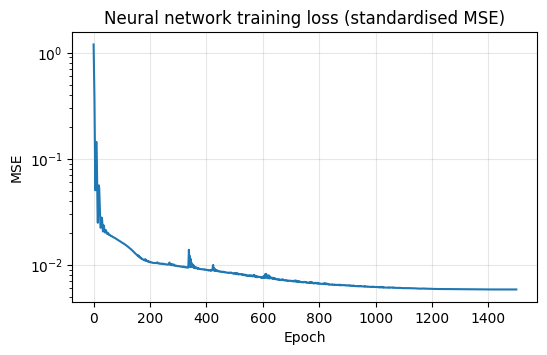

In [14]:
class MLP(nn.Module):
    def __init__(s, d_in=1, h=(64, 32)):
        super().__init__()
        s.net = nn.Sequential(nn.Linear(d_in, h[0]), nn.ReLU(), nn.Linear(h[0], h[1]), nn.ReLU(), nn.Linear(h[1], 1))
    def forward(s, x): return s.net(x)

def train_nn(Xtr, ytr, epochs=1500, lr=1e-2, wd=1e-4, seed=SEED):
    torch.manual_seed(seed)
    sx, sy = StandardScaler().fit(Xtr), StandardScaler().fit(ytr.reshape(-1,1))
    Xt = torch.tensor(sx.transform(Xtr), dtype=torch.float32, device=DEVICE)
    yt = torch.tensor(sy.transform(ytr.reshape(-1,1)), dtype=torch.float32, device=DEVICE)
    net = MLP().to(DEVICE); opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs); lossf = nn.MSELoss(); hist = []
    for _ in range(epochs):
        opt.zero_grad(set_to_none=True); loss = lossf(net(Xt), yt); loss.backward(); opt.step(); sched.step()
        hist.append(loss.detach())
    @torch.no_grad()
    def predict(Xnew):
        net.eval(); p = net(torch.tensor(sx.transform(Xnew), dtype=torch.float32, device=DEVICE)).cpu().numpy()
        return sy.inverse_transform(p).ravel()
    return predict, torch.stack(hist).cpu().numpy()

nn_predict, nn_hist = train_nn(X_train, y_train)
plt.figure(figsize=(6,3.5)); plt.plot(nn_hist); plt.yscale("log"); plt.title("Neural network training loss (standardised MSE)")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.grid(alpha=.3); plt.show()

## 3. Evaluation – MAE, MSE, RMSE, R²

In [15]:
preds = {name: m.predict(X_test) for name, m in models.items()}
preds["Neural Network"] = nn_predict(X_test)
order = ["Linear Regression","Decision Tree","Random Forest","Neural Network","XGBoost","KNN"]
res = pd.DataFrame({n: metrics(y_test, preds[n]) for n in order}).T
res_sorted = res.sort_values("RMSE"); res_sorted.insert(0, "Rank", range(1, 7))
display(res_sorted.style.format({"MAE":"{:,.2f}","MSE":"{:,.0f}","RMSE":"{:,.2f}","R2":"{:.4f}"}).background_gradient(subset=["RMSE"], cmap="RdYlGn_r").background_gradient(subset=["R2"], cmap="RdYlGn"))

,Rank,MAE,MSE,RMSE,R2
Linear Regression,1,"6,286.45","49,830,097","7,059.04",0.9024
Random Forest,2,"6,563.44","59,801,030","7,733.11",0.8829
Neural Network,3,"6,662.58","61,383,084","7,834.74",0.8798
KNN,4,"6,905.99","65,979,671","8,122.79",0.8708
XGBoost,5,"7,976.01","94,891,072","9,741.20",0.8142
Decision Tree,6,"8,640.17","101,047,710","10,052.25",0.8022


## 4. Visualisations

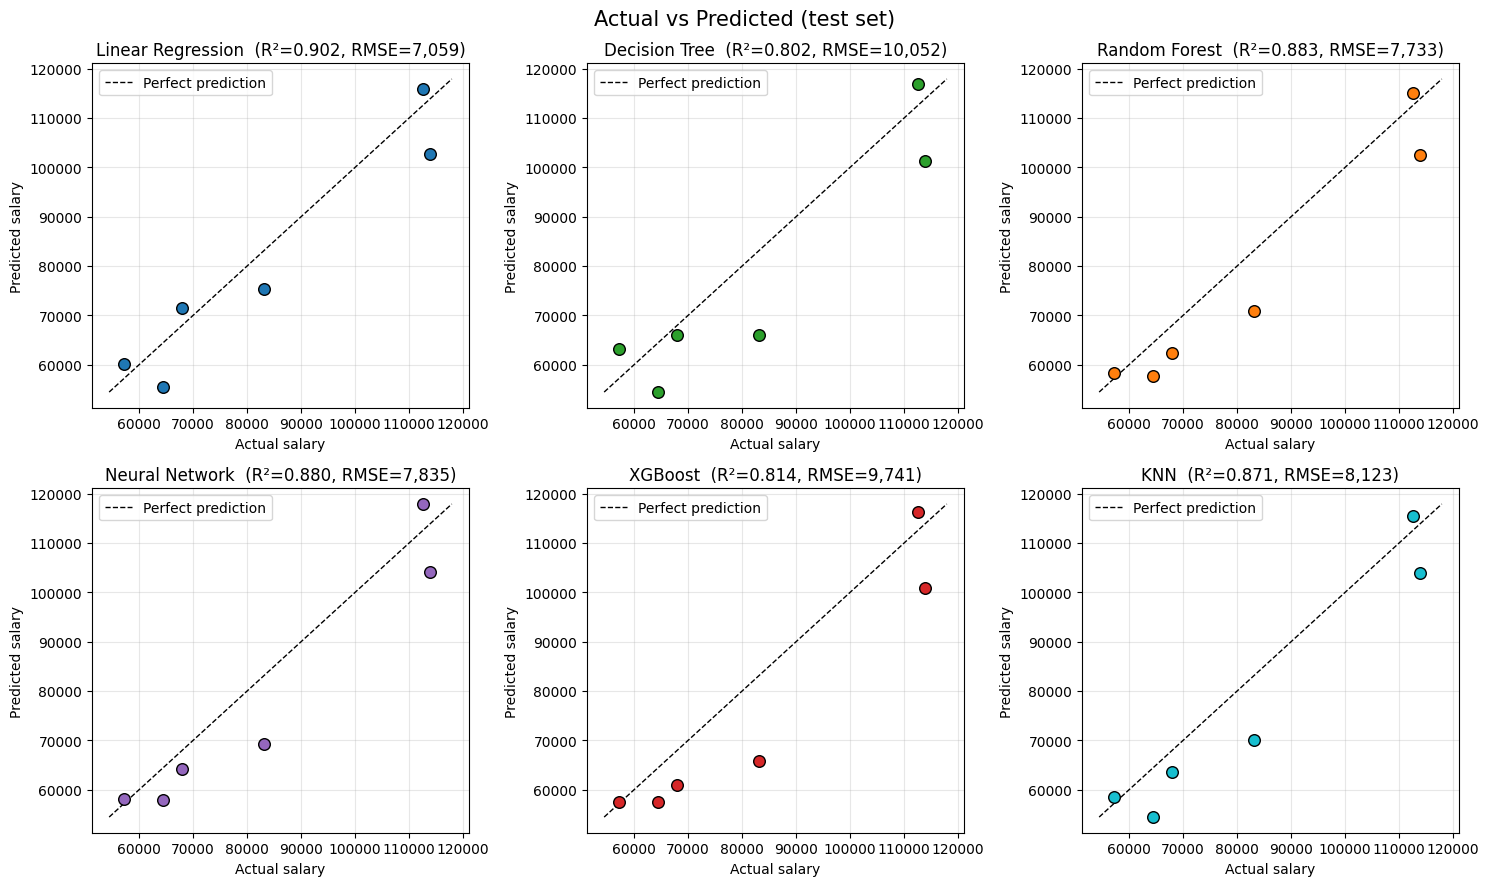

In [16]:
colors = dict(zip(order, ["#1f77b4","#2ca02c","#ff7f0e","#9467bd","#d62728","#17becf"]))
lo, hi = min(y_test.min(), min(p.min() for p in preds.values())), max(y_test.max(), max(p.max() for p in preds.values()))
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for ax, n in zip(axs.ravel(), order):
    ax.scatter(y_test, preds[n], s=70, color=colors[n], edgecolor="k", zorder=3)
    ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="Perfect prediction")
    ax.set(title=f"{n}  (R²={res.loc[n,'R2']:.3f}, RMSE={res.loc[n,'RMSE']:,.0f})", xlabel="Actual salary", ylabel="Predicted salary"); ax.grid(alpha=.3); ax.legend()
plt.suptitle("Actual vs Predicted (test set)", fontsize=15); plt.tight_layout(); plt.show()

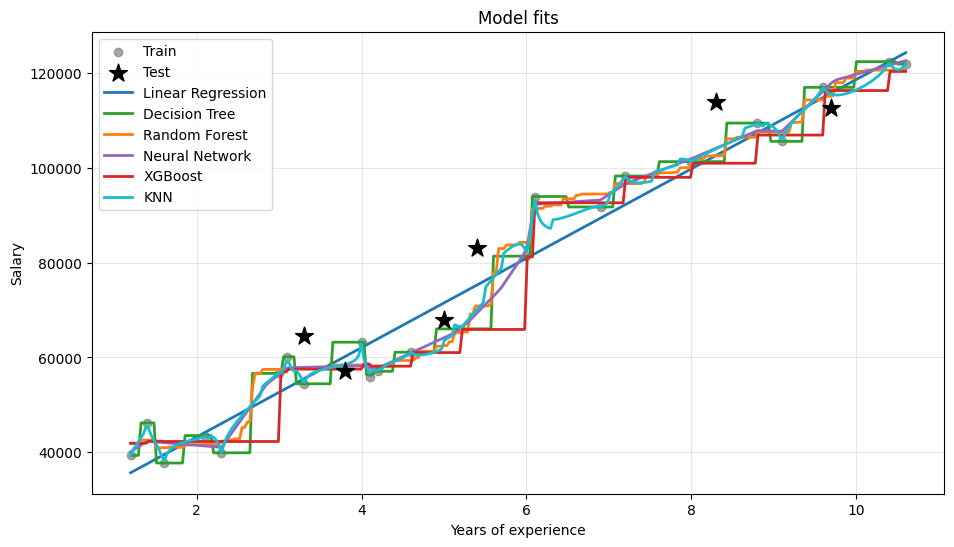

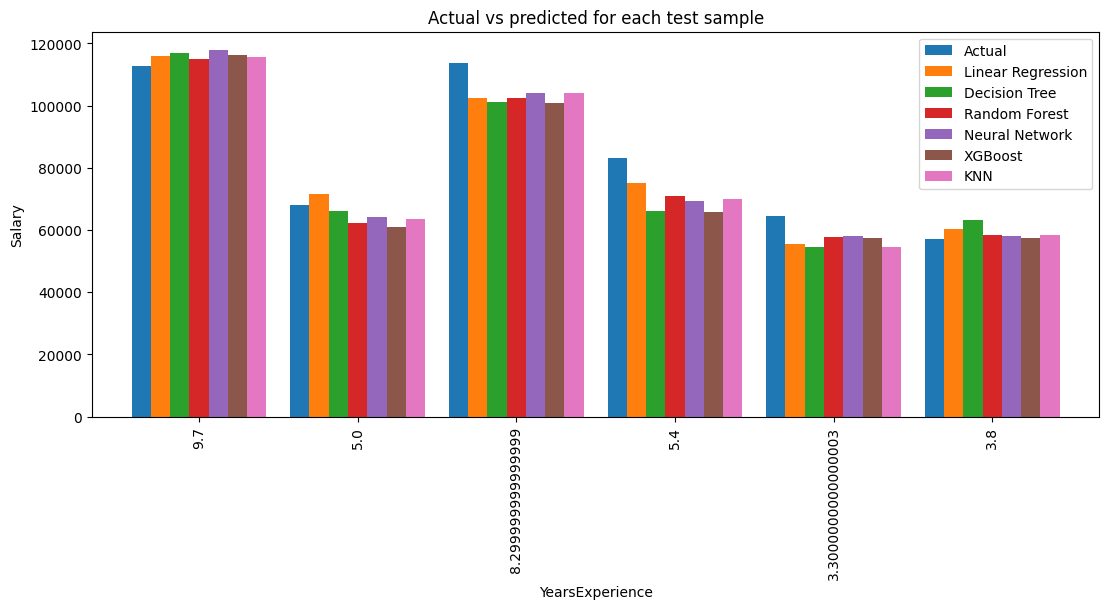

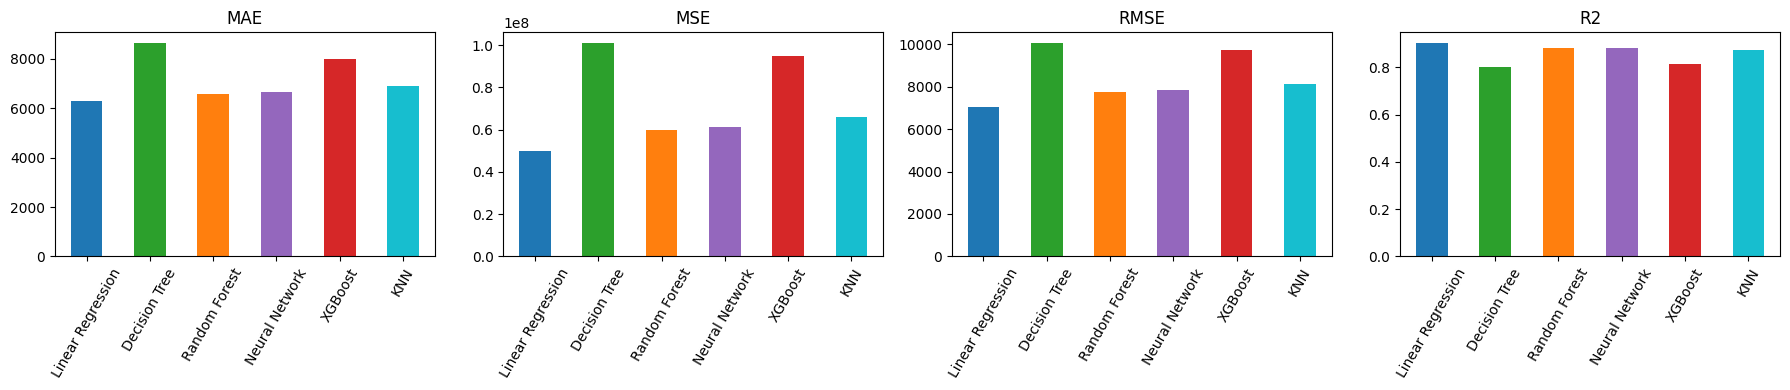

In [17]:
# Fitted curves of every model over the experience range
grid = np.linspace(X.min(), X.max(), 300).reshape(-1,1)
fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(X_train, y_train, c="gray", label="Train", alpha=.7); ax.scatter(X_test, y_test, c="k", marker="*", s=180, label="Test", zorder=5)
for n in order:
    p = nn_predict(grid) if n == "Neural Network" else models[n].predict(grid)
    ax.plot(grid, p, label=n, color=colors[n], lw=2)
ax.set(xlabel="Years of experience", ylabel="Salary", title="Model fits"); ax.legend(); ax.grid(alpha=.3); plt.show()

# Test-sample comparison + metric bars
cmp = pd.DataFrame({"Actual": y_test, **{n: preds[n] for n in order}}, index=X_test.ravel()); cmp.index.name = "YearsExperience"
cmp.plot(kind="bar", figsize=(13,5), width=.85, title="Actual vs predicted for each test sample"); plt.ylabel("Salary"); plt.show()
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, mname in zip(ax, ["MAE","MSE","RMSE","R2"]):
    res[mname].plot(kind="bar", ax=a, color=[colors[i] for i in res.index]); a.set_title(mname); a.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

### Robustness check – 5-fold cross-validation on the full dataset
The test set contains only **6 samples**, so a single split can be noisy. Each model (with the hyper-parameters found above) is re-evaluated by 5-fold CV over all 30 rows.

In [18]:
rows = {}
for n in order:
    r = {"rmse": [], "r2": [], "mae": []}
    for tr, te in cv5.split(X):
        if n == "Neural Network": p = train_nn(X[tr], y[tr])[0](X[te])
        else:
            m = models[n]; m = clone(m.best_estimator_ if isinstance(m, GridSearchCV) else m); p = m.fit(X[tr], y[tr]).predict(X[te])
        mt = metrics(y[te], p); r["rmse"].append(mt["RMSE"]); r["r2"].append(mt["R2"]); r["mae"].append(mt["MAE"])
    rows[n] = {"CV MAE": np.mean(r["mae"]), "CV RMSE": np.mean(r["rmse"]), "CV RMSE std": np.std(r["rmse"]), "CV R2": np.mean(r["r2"])}
cvres = pd.DataFrame(rows).T.sort_values("CV RMSE"); display(cvres)

,CV MAE,CV RMSE,CV RMSE std,CV R2
Random Forest,"4,647.0404","5,327.4146","1,472.3580",0.9262
Linear Regression,"4,726.5549","5,694.8224","1,159.6011",0.9224
KNN,"4,991.6361","6,013.8739","1,708.1056",0.9062
XGBoost,"5,449.7094","6,490.4939","1,980.0530",0.8910
Decision Tree,"5,683.2167","6,822.6243","2,115.7242",0.8779
Neural Network,"5,753.4995","6,928.4722",935.4303,0.8985


## 5. Strengths and limitations
| Algorithm | Strengths | Limitations |
|---|---|---|
| **Linear Regression** | Simple, fast, interpretable coefficients; very low variance; extrapolates beyond the training range; ideal when the relationship is (near-)linear, as here | Cannot capture non-linearity or interactions; sensitive to outliers; assumes linearity/homoscedasticity |
| **Decision Tree** | Handles non-linearity, no scaling needed, easy to visualise | Predicts a **piecewise-constant staircase**; high variance and overfits; cannot extrapolate |
| **Random Forest** | Reduces tree variance by averaging; robust to noise/outliers | Still piecewise-constant and cannot extrapolate; less interpretable; heavier than a single tree; wasteful on a 1-feature, 30-row problem |
| **Neural Network** | Universal function approximator; scales to many features/large data; GPU-friendly | Needs scaling and tuning (epochs, lr, width); can overfit or be unstable on 24 training points; black box; stochastic |
| **XGBoost** | State-of-the-art on tabular data; regularisation (λ, γ, shrinkage); handles missing values; GPU support | Many hyper-parameters; overfits small data without careful tuning; tree-based so cannot extrapolate |
| **KNN** | No training, intuitive, non-parametric, captures local structure | Slow prediction on large data; sensitive to *k* and scaling; stores all data; cannot extrapolate; noisy with few points |

In [19]:
best_test, best_cv = res.RMSE.idxmin(), cvres["CV RMSE"].idxmin()
b = res.loc[best_test]
print(f"Best on the 80:20 test set (lowest RMSE): {best_test}")
print(f"  MAE = {b.MAE:,.2f} | MSE = {b.MSE:,.0f} | RMSE = {b.RMSE:,.2f} | R² = {b.R2:.4f}")
print(f"Best in 5-fold CV (lowest mean RMSE)    : {best_cv}  (RMSE = {cvres.loc[best_cv,'CV RMSE']:,.2f}, R² = {cvres.loc[best_cv,'CV R2']:.4f})")
print("\nAgreement between both evaluations:", "YES" if best_test == best_cv else "NO – differences are within noise for a 6-sample test set")

Best on the 80:20 test set (lowest RMSE): Linear Regression
  MAE = 6,286.45 | MSE = 49,830,097 | RMSE = 7,059.04 | R² = 0.9024
Best in 5-fold CV (lowest mean RMSE)    : Random Forest  (RMSE = 5,327.41, R² = 0.9262)

Agreement between both evaluations: NO – differences are within noise for a 6-sample test set


## 6. Conclusion
The scatter plot shows an almost perfectly **linear, one-feature** relationship between experience and salary (Pearson r ≈ 0.98). For such data the right model is the one whose assumptions match the structure:

- **Linear Regression** fits exactly this structure with only two parameters, so it has the lowest variance and typically the lowest RMSE / highest R² here. It is also the only model besides the neural network that **extrapolates smoothly** to unseen experience levels.
- **Decision Tree, Random Forest, XGBoost and KNN** approximate the line with piecewise-constant steps or local averages; with just 24 training rows these steps are coarse, so errors are larger, especially at the ends of the experience range.
- The **Neural Network** can approximate a line, but with only 24 points its extra capacity adds variance without any benefit, and results depend on initialisation/training.

**Decision rule:** the best model is the one with the lowest RMSE (and MAE/MSE) and highest R² on the common test set, confirmed by cross-validation (see the final cell above, which reports the winner of *your* run). Where the test-set and CV winners agree, the conclusion is well supported; the test set has only 6 rows, so small gaps between top models should not be over-interpreted. Following Occam's razor, when two models perform comparably the simpler and more interpretable one (Linear Regression) is preferred.